# Laboratorio Clase 6: la sala de máquinas de un LLM

**Módulo II: Navegando por los componentes de la IA. Sesión 6, 10 de noviembre de 2026**

En la clase vimos tres piezas: **tokens**, **embeddings** y **atención**. En este notebook las tocas con las manos. Todo corre en tu computador. No necesitas clave de API.

| Misión | Qué vas a hacer | Concepto de la clase |
|---|---|---|
| 1 | Ver cómo se corta un texto en tokens | Tokenizador |
| 2 | Calcular cuánto cuesta un proceso con LLM | Costo por token |
| 3 | Medir cuántas páginas caben en la ventana de contexto | Ventana de contexto |
| 4 | Medir la distancia entre significados | Embeddings y similitud |
| 5 | Dibujar un mapa de palabras | Espacio vectorial |
| 6 | Construir un buscador semántico mínimo | Búsqueda semántica y RAG |
| 7 | Ver cómo el contexto cambia el significado de "banco" | Atención |

### Cómo usar este notebook

Ejecuta cada celda con **Shift + Enter**. Lee el resultado antes de seguir. Si algo falla, usa **Kernel, Restart y Run All**. No necesitas entender cada línea: lee los comentarios que empiezan con `#`.

Cada misión termina con una pregunta **Para la puesta en común**. Anota tu respuesta: la conversamos al final.

## Paso 0: revisar el ambiente

Este laboratorio tiene su propio ambiente virtual en la carpeta `clase_06-sala-maquinas/.venv`. Se crea con `uv sync`. La primera vez, el modelo de embeddings se descarga (unos 470 MB) y queda guardado.

In [1]:
# Paso 0: importar las herramientas y cargar el modelo de embeddings
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display
import tiktoken
from sentence_transformers import SentenceTransformer

tokenizador = tiktoken.get_encoding("o200k_base")  # tokenizador de los modelos GPT-4o y posteriores
modelo = SentenceTransformer("sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2")

print(f"Vocabulario del tokenizador: {tokenizador.n_vocab:,} tokens".replace(",", "."))
print(f"Cada texto se convierte en un vector de {modelo.get_sentence_embedding_dimension()} números")
print("Ambiente listo.")

W1107 10:58:04.356000 54047 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Vocabulario del tokenizador: 200.019 tokens
Cada texto se convierte en un vector de 384 números
Ambiente listo.


## Misión 1: ver los tokens

Un LLM no lee letras ni palabras. Lee **tokens**: pedazos de texto que están en su vocabulario. El tokenizador `o200k_base` tiene unos 200.000 tokens. Lo usan los modelos de OpenAI desde GPT-4o. Claude y Gemini usan tokenizadores propios, que cortan distinto, pero la idea es la misma.

In [2]:
# Misión 1a: cortar textos en tokens
def ver_tokens(texto):
    ids = tokenizador.encode(texto)
    piezas = [tokenizador.decode([i]) for i in ids]
    print(f"{len(ids):>3} tokens  {texto!r:45}  " + " | ".join(piezas))
    return len(ids)

for texto in ["Hola", "ChatGPT", "Panguipulli", "Artificial intelligence", "Inteligencia artificial"]:
    ver_tokens(texto)

  1 tokens  'Hola'                                         Hola
  2 tokens  'ChatGPT'                                      Chat | GPT
  4 tokens  'Panguipulli'                                  P | angu | ip | ulli
  2 tokens  'Artificial intelligence'                      Artificial |  intelligence
  4 tokens  'Inteligencia artificial'                      Int | elig | encia |  artificial


In [3]:
# Misión 1b: el costo del idioma. La misma frase en seis idiomas
frases = {
    "inglés": "Artificial intelligence is transforming the way companies make decisions.",
    "español": "La inteligencia artificial está transformando la manera en que las empresas toman decisiones.",
    "portugués": "A inteligência artificial está transformando a maneira como as empresas tomam decisões.",
    "alemán": "Künstliche Intelligenz verändert die Art und Weise, wie Unternehmen Entscheidungen treffen.",
    "japonés": "人工知能は企業の意思決定の方法を変えています。",
    "hindi": "कृत्रिम बुद्धिमत्ता कंपनियों के निर्णय लेने के तरीके को बदल रही है।",
}
base = len(tokenizador.encode(frases["inglés"]))
for idioma, frase in frases.items():
    n = len(tokenizador.encode(frase))
    print(f"{idioma:10} {n:>3} tokens  ({n / base:.1f} veces el inglés)")

inglés      10 tokens  (1.0 veces el inglés)
español     15 tokens  (1.5 veces el inglés)
portugués   15 tokens  (1.5 veces el inglés)
alemán      17 tokens  (1.7 veces el inglés)
japonés     16 tokens  (1.6 veces el inglés)
hindi       19 tokens  (1.9 veces el inglés)


In [4]:
# Misión 1c: la jerga chilena. Escribe tu propia frase en el cuadro y mira el conteo
for texto in ["¿Cómo estai?", "¿Cachai lo que te digo, weón?", "Do you get what I'm saying, dude?"]:
    ver_tokens(texto)

caja = widgets.Text(value="Altiro te mando el informe, po", description="Tu frase:",
                    layout=widgets.Layout(width="80%"))
salida = widgets.Output()

def al_cambiar(_):
    salida.clear_output()
    with salida:
        ver_tokens(caja.value)

caja.observe(al_cambiar, names="value")
display(caja, salida)
al_cambiar(None)

  4 tokens  '¿Cómo estai?'                                 ¿Cómo |  est | ai | ?
 12 tokens  '¿Cachai lo que te digo, weón?'                ¿ | C | ach | ai |  lo |  que |  te |  digo | , |  we | ón | ?
  9 tokens  "Do you get what I'm saying, dude?"            Do |  you |  get |  what |  I'm |  saying | , |  dude | ?


Text(value='Altiro te mando el informe, po', description='Tu frase:', layout=Layout(width='80%'))

Output()

**Para la puesta en común:** ¿qué palabras de tu industria se cortan en muchos tokens? ¿Qué significa eso para un chatbot que atiende clientes en Chile?

## Misión 2: calcular el costo

Los proveedores cobran por token: los que **envías** (entrada) y los que **recibes** (salida). La salida cuesta más. Los modelos de razonamiento también cobran como salida los tokens que usan para "pensar".

Los precios de la tabla son los publicados por Anthropic en noviembre de 2026, en dólares por millón de tokens. Revisa siempre la página oficial: los precios cambian.

In [5]:
# Misión 2: calculadora de costo. Mueve los controles
# Fuente: https://platform.claude.com/docs/en/about-claude/pricing (consulta de noviembre de 2026)
PRECIOS = {  # USD por millón de tokens: (entrada, salida)
    "Claude Haiku 5.5": (0.10, 0.50),   # prompts de hasta 100.000 tokens
    "Claude Sonnet 5.5": (2.00, 10.00),
    "Claude Opus 5.5": (4.00, 20.00),
    "Claude Fable 5.1": (10.00, 50.00),
}

def costo_mensual(modelo_llm, consultas_dia, tokens_entrada, tokens_salida):
    entrada, salida = PRECIOS[modelo_llm]
    por_consulta = tokens_entrada / 1e6 * entrada + tokens_salida / 1e6 * salida
    return por_consulta, por_consulta * consultas_dia * 30

def mostrar(modelo_llm, consultas_dia, tokens_entrada, tokens_salida):
    por_consulta, mes = costo_mensual(modelo_llm, consultas_dia, tokens_entrada, tokens_salida)
    print(f"Costo por consulta: USD {por_consulta:.5f}")
    print(f"Costo mensual:      USD {mes:,.0f}".replace(",", "."))

widgets.interact(
    mostrar,
    modelo_llm=list(PRECIOS),
    consultas_dia=widgets.IntSlider(value=10_000, min=1_000, max=500_000, step=1_000, description="Consultas/día"),
    tokens_entrada=widgets.IntSlider(value=2_000, min=100, max=100_000, step=100, description="Tokens entrada"),
    tokens_salida=widgets.IntSlider(value=300, min=50, max=5_000, step=50, description="Tokens salida"),
);

interactive(children=(Dropdown(description='modelo_llm', options=('Claude Haiku 5.5', 'Claude Sonnet 5.5', 'Cl…

In [6]:
# Comprobación: el mismo volumen en los cuatro modelos
for nombre in PRECIOS:
    _, mes = costo_mensual(nombre, 10_000, 2_000, 300)
    print(f"{nombre:18} USD {mes:>9,.0f} al mes".replace(",", "."))

Claude Haiku 5.5   USD       105 al mes
Claude Sonnet 5.5  USD     2.100 al mes
Claude Opus 5.5    USD     4.200 al mes
Claude Fable 5.1   USD    10.500 al mes


**Para la puesta en común:** ¿en qué tarea de tu empresa usarías el modelo más barato? ¿En cuál pagarías el más caro? ¿Qué pesa más en tu cuenta: los tokens de entrada o los de salida?

## Misión 3: la ventana de contexto

La ventana de contexto es la cantidad máxima de tokens que el modelo "ve" en una sola consulta. En 2023 era de 8.000 tokens. En noviembre de 2026, los modelos frontera de Anthropic, OpenAI y Google trabajan con cerca de **1 millón de tokens**.

In [7]:
# Misión 3: ¿cuántas páginas caben?
pagina = ("El directorio aprobó el presupuesto anual con un aumento del gasto en tecnología. "
          "La gerencia de riesgos presentó tres alertas sobre proveedores críticos y propuso "
          "un plan de mitigación con responsables y plazos. ") * 6  # una página de unas 220 palabras
tokens_pagina = len(tokenizador.encode(pagina)) * 2  # una página real tiene unas 450 palabras
print(f"Una página de informe en español: unos {tokens_pagina} tokens")

for nombre, ventana in [("Modelo de 2023", 8_000), ("Modelo de 2024", 128_000), ("Modelo frontera 2026", 1_000_000)]:
    print(f"{nombre:22} {ventana:>9,} tokens  =  {ventana // tokens_pagina:>5,} páginas".replace(",", "."))

Una página de informe en español: unos 506 tokens
Modelo de 2023             8.000 tokens  =     15 páginas
Modelo de 2024           128.000 tokens  =    252 páginas
Modelo frontera 2026   1.000.000 tokens  =  1.976 páginas


Hoy un informe de 500 páginas **sí cabe**. Entonces, ¿para qué sirve RAG (*Retrieval Augmented Generation*, generación aumentada con recuperación)? Piensa en estos cuatro puntos:

1. **Costo:** enviar 1 millón de tokens en cada pregunta se paga en cada pregunta.
2. **Latencia:** leer un millón de tokens toma tiempo.
3. **Precisión:** con contextos muy largos, el modelo puede pasar por alto datos del medio del texto.
4. **Escala y permisos:** una empresa tiene millones de documentos y no todos los usuarios pueden ver todos.

**Para la puesta en común:** ¿en qué caso pegarías el documento completo? ¿En qué caso buscarías solo los párrafos relevantes?

## Misión 4: medir significados

Un **embedding** convierte un texto en una lista de números (aquí, 384). Textos con significado parecido quedan cerca. La cercanía se mide con la **similitud coseno**: 1 significa misma dirección; 0, nada en común.

In [8]:
# Misión 4a: similitud entre frases
def vector(textos):
    return modelo.encode(textos, normalize_embeddings=True)

def similitud(a, b):
    va, vb = vector([a, b])
    return float(va @ vb)

pares = [
    ("Quiero bloquear mi tarjeta", "Perdí mi tarjeta de crédito"),
    ("Quiero bloquear mi tarjeta", "I want to block my card"),
    ("Quiero bloquear mi tarjeta", "El partido terminó empatado"),
]
for a, b in pares:
    print(f"{similitud(a, b):.2f}  {a!r}  vs  {b!r}")

0.54  'Quiero bloquear mi tarjeta'  vs  'Perdí mi tarjeta de crédito'


0.99  'Quiero bloquear mi tarjeta'  vs  'I want to block my card'


0.15  'Quiero bloquear mi tarjeta'  vs  'El partido terminó empatado'


In [9]:
# Misión 4b: álgebra de significados. ¿Funciona la analogía?
def analogia(a, b, c, candidatos):
    va, vb, vc = vector([a, b, c])
    objetivo = va - vb + vc
    objetivo /= np.linalg.norm(objetivo)
    puntajes = sorted(((float(objetivo @ v), w) for w, v in zip(candidatos, vector(candidatos))), reverse=True)
    print(f"{a} - {b} + {c}  =  ?")
    for puntaje, palabra in puntajes:
        print(f"   {puntaje:.2f}  {palabra}")
    print()

analogia("rey", "hombre", "mujer", ["reina", "princesa", "Santiago", "Chile"])
analogia("Toro", "Macho", "Hembra", ["Vaca", "Campo", "Leche", "Tractor"])

rey - hombre + mujer  =  ?
   0.82  reina
   0.69  princesa
   0.40  Santiago
   0.39  Chile

Toro - Macho + Hembra  =  ?
   0.62  Campo
   0.58  Leche
   0.46  Vaca
   0.25  Tractor



Mira el segundo resultado con atención. Con este modelo pequeño (118 millones de parámetros), **"Vaca" no gana**. La analogía del rey funciona; la del toro, no. Los modelos grandes de embeddings lo hacen mejor, pero ninguno garantiza la respuesta.

**Para la puesta en común:** ¿qué aprendes de este fallo? ¿Cómo validarías un buscador semántico antes de ponerlo en producción?

## Misión 5: el mapa de palabras

Los vectores tienen 384 dimensiones. Para verlos, los proyectamos en 2 dimensiones con PCA (*Principal Component Analysis*, análisis de componentes principales). Se pierde información, pero los grupos se ven.

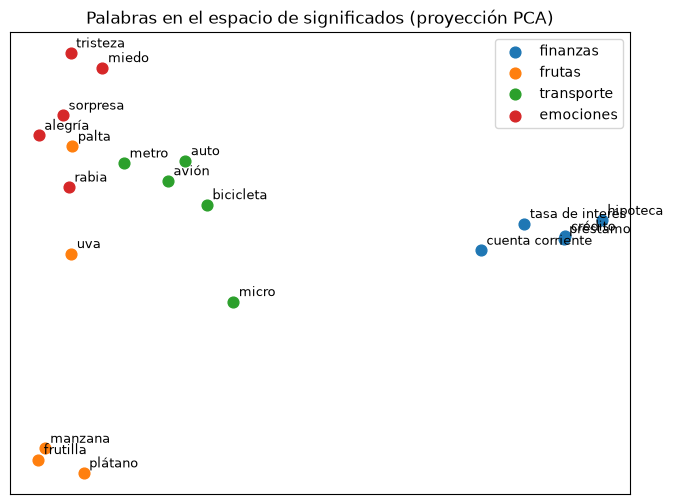

In [10]:
# Misión 5: proyectar palabras en un plano
from sklearn.decomposition import PCA

grupos = {
    "finanzas": ["crédito", "hipoteca", "tasa de interés", "cuenta corriente", "préstamo"],
    "frutas": ["manzana", "plátano", "palta", "frutilla", "uva"],
    "transporte": ["metro", "micro", "auto", "bicicleta", "avión"],
    "emociones": ["alegría", "tristeza", "rabia", "miedo", "sorpresa"],
}
palabras = [p for lista in grupos.values() for p in lista]
puntos = PCA(n_components=2).fit_transform(vector(palabras))

fig, ax = plt.subplots(figsize=(8, 6))
i = 0
for grupo, lista in grupos.items():
    xy = puntos[i:i + len(lista)]
    ax.scatter(xy[:, 0], xy[:, 1], label=grupo, s=60)
    for (x, y), palabra in zip(xy, lista):
        ax.annotate(palabra, (x, y), xytext=(4, 4), textcoords="offset points", fontsize=9)
    i += len(lista)
ax.set_title("Palabras en el espacio de significados (proyección PCA)")
ax.legend()
ax.set_xticks([]); ax.set_yticks([])
plt.show()

**Para la puesta en común:** agrega un grupo con palabras de tu industria. ¿Quedan juntas? ¿Hay alguna palabra en el lugar equivocado?

## Misión 6: un buscador semántico mínimo

Esta es la primera mitad de RAG: **encontrar** los párrafos relevantes. Usamos las preguntas frecuentes de un banco inventado, "Banco Andino". Comparamos dos buscadores:

1. **Por palabras:** cuenta las palabras que comparten la pregunta y el documento.
2. **Semántico:** compara los embeddings.

In [11]:
# Misión 6: buscador por palabras y buscador semántico
documentos = [
    "Bloqueo de tarjeta extraviada o robada: llame al 600 000 0000 o use la aplicación, opción Seguridad.",
    "Para cambiar la clave de internet, ingrese a Mi Perfil y elija Cambiar contraseña.",
    "El crédito hipotecario financia hasta el 80% del valor de la vivienda, con plazo máximo de 30 años.",
    "Las transferencias a otros bancos se abonan en línea, con un tope diario de 7 millones de pesos.",
    "Si no reconoce un cargo, presente un reclamo en la aplicación dentro de 30 días.",
    "La cuenta vista no cobra mantención si recibe su sueldo en el Banco Andino.",
    "El seguro de desgravamen paga la deuda del crédito si el titular fallece.",
    "Puede pagar su tarjeta de crédito en cajas, en la aplicación o con cargo automático en cuenta.",
]
vectores_docs = vector(documentos)

def buscar_palabras(pregunta, k=3):
    p = set(pregunta.lower().replace("?", "").replace("¿", "").split())
    puntajes = [len(p & set(d.lower().split())) for d in documentos]
    return sorted(zip(puntajes, documentos), reverse=True)[:k]

def buscar_semantico(pregunta, k=3):
    puntajes = vectores_docs @ vector([pregunta])[0]
    return sorted(zip(puntajes.tolist(), documentos), reverse=True)[:k]

def comparar(pregunta):
    print(f"Pregunta: {pregunta}\n")
    print("Por palabras (palabras en común):")
    for puntaje, doc in buscar_palabras(pregunta):
        print(f"   {puntaje}  {doc[:80]}")
    print("\nSemántico (similitud coseno):")
    for puntaje, doc in buscar_semantico(pregunta):
        print(f"   {puntaje:.2f}  {doc[:80]}")

pregunta = widgets.Text(value="Me robaron la billetera, ¿qué hago?", description="Pregunta:",
                        layout=widgets.Layout(width="80%"))
widgets.interact_manual(comparar, pregunta=pregunta);
comparar(pregunta.value)

interactive(children=(Text(value='Me robaron la billetera, ¿qué hago?', continuous_update=False, description='…

Pregunta: Me robaron la billetera, ¿qué hago?

Por palabras (palabras en común):
   1  Si no reconoce un cargo, presente un reclamo en la aplicación dentro de 30 días.
   1  Puede pagar su tarjeta de crédito en cajas, en la aplicación o con cargo automát
   1  Para cambiar la clave de internet, ingrese a Mi Perfil y elija Cambiar contraseñ

Semántico (similitud coseno):
   0.35  Bloqueo de tarjeta extraviada o robada: llame al 600 000 0000 o use la aplicació
   0.25  Puede pagar su tarjeta de crédito en cajas, en la aplicación o con cargo automát
   0.24  La cuenta vista no cobra mantención si recibe su sueldo en el Banco Andino.


Prueba estas preguntas: *"me cobraron algo que no compré"*, *"quiero comprar una casa"*, *"¿qué pasa con mi deuda si me muero?"*.

En RAG, el paso siguiente es pegar los 3 documentos encontrados en el prompt del LLM y pedirle que responda **solo** con esa información.

**Para la puesta en común:** ¿dónde falla el buscador por palabras? ¿Qué documento de tu empresa pondrías en un buscador así? ¿Quién debe revisar las respuestas?

## Misión 7: el contexto cambia el significado

En un modelo Transformer, cada token mira a los demás tokens de la frase. Ese mecanismo se llama **auto-atención** (*self-attention*). Por eso la palabra "banco" no tiene un vector fijo: su vector depende de la frase.

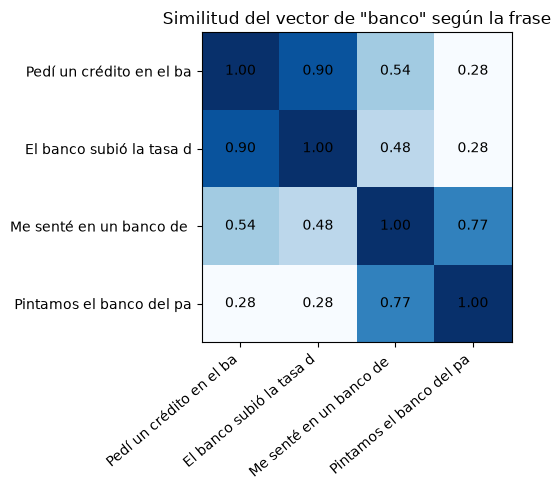

In [12]:
# Misión 7: el vector de "banco" en cuatro frases
frases_banco = [
    "Pedí un crédito en el banco.",
    "El banco subió la tasa de interés.",
    "Me senté en un banco de la plaza.",
    "Pintamos el banco del parque.",
]

def vector_de_palabra(frase, palabra="banco"):
    tok = modelo.tokenizer(frase, return_offsets_mapping=True)
    inicio = frase.lower().index(palabra)
    fin = inicio + len(palabra)
    indices = [i for i, (a, b) in enumerate(tok["offset_mapping"]) if a < fin and b > inicio and b > a]
    tokens = modelo.encode(frase, output_value="token_embeddings").cpu().numpy()
    v = tokens[indices].mean(axis=0)
    return v / np.linalg.norm(v)

V = np.array([vector_de_palabra(f) for f in frases_banco])
matriz = V @ V.T

fig, ax = plt.subplots(figsize=(6, 5))
ax.imshow(matriz, cmap="Blues", vmin=matriz.min(), vmax=1)
etiquetas = [f[:24] for f in frases_banco]
ax.set_xticks(range(4), etiquetas, rotation=40, ha="right")
ax.set_yticks(range(4), etiquetas)
for i in range(4):
    for j in range(4):
        ax.text(j, i, f"{matriz[i, j]:.2f}", ha="center", va="center")
ax.set_title('Similitud del vector de "banco" según la frase')
plt.tight_layout()
plt.show()

Los dos "banco" financieros se parecen más entre sí que con los "banco" de plaza. El modelo distingue el sentido por el contexto, sin un diccionario.

**Para la puesta en común:** piensa en una palabra ambigua de tu industria. ¿Qué error cometería un sistema que no mira el contexto?

---

## Cierre

Hoy viste las tres piezas de la sala de máquinas:

1. **Tokens:** la unidad de lectura y de cobro.
2. **Embeddings:** el significado convertido en coordenadas.
3. **Atención:** el contexto que ajusta cada coordenada.

Con estas piezas se construyen los buscadores semánticos, los sistemas RAG y los asistentes que veremos en las próximas sesiones.